# ~ MARS Demo ~

## Import Libraries

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from patsy import dmatrix
import statsmodels.api as sm
import statsmodels.formula.api as smf
from math import sqrt
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.neural_network import MLPRegressor
import warnings

## Data Exploration

In [26]:
unrate = pd.read_csv("~/Downloads/UNRATE.csv")
unrate = unrate.dropna()

#view sample of data
display(unrate.head(10))


,DATE,UNRATE
0,1948-01-01,3.4
1,1948-02-01,3.8
2,1948-03-01,4.0
3,1948-04-01,3.9
4,1948-05-01,3.5
5,1948-06-01,3.6
6,1948-07-01,3.6
7,1948-08-01,3.9
8,1948-09-01,3.8
9,1948-10-01,3.7


## Data preprocessing & visualisation

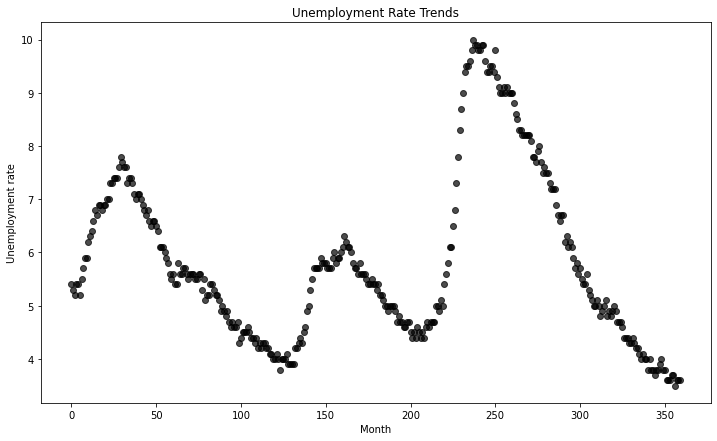

In [27]:
#Using data from years 1990 to 2019 

x = []

#Data is on monthly basis:
#as of 1st jan 1990 - Month = 0
#as of 1st feb 1990 - Month = 1
#and so on...

for i in range(0,360):
    x.append(i)

X = np.array(x)  #predictor
y = unrate.iloc[504:864]['UNRATE'] #target


#plot
plt.figure(figsize=(12, 7))
plt.scatter(X, y, facecolor='None', edgecolor='k', alpha=0.7, c="black")
plt.xlabel('Month')
plt.ylabel('Unemployment rate')
plt.title("Unemployment Rate Trends")
plt.show()

## Split data

In [28]:
#split dataset
train_x, test_x, train_y, test_y = train_test_split(X, y, test_size=0.2, random_state = 5)

#to be used for plots
test_x = np.array(test_x)
x_test = test_x
train_x = np.array(train_x)
x_test.sort()

## Linear Regression

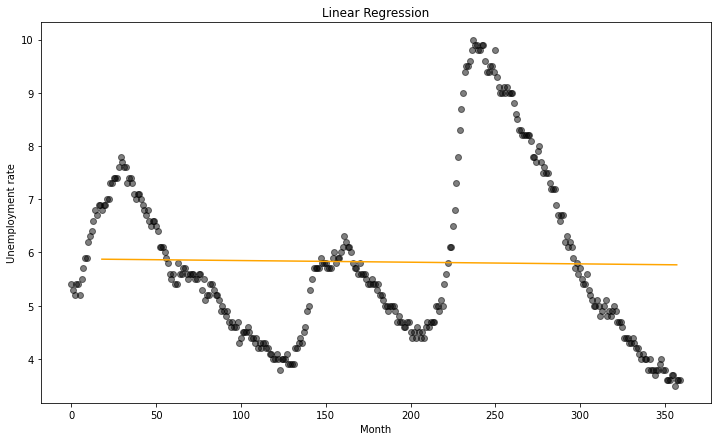

MSE of linear: 2.499910564374394
R2 of linear: -0.013670680225272847


In [29]:
#linear regression
model = LinearRegression()
tx = train_x.reshape(-1,1)
model.fit(tx,train_y)

ttx = test_x.reshape(-1,1)
pred_linear = model.predict(ttx)

#plot
plt.figure(figsize=(12, 7))
plt.scatter(X, y, facecolor='None', edgecolor='k', alpha=0.5, c="black")
plt.plot(x_test, pred_linear, c="orange")
plt.xlabel('Month')
plt.ylabel('Unemployment rate')
plt.title("Linear Regression")
plt.show()

#mse
mse_linear = mean_squared_error(test_y, pred_linear)
print("MSE of linear:",mse_linear)

#R2
r2_linear = r2_score(test_y, pred_linear)
print("R2 of linear:",r2_linear)

## Polynomial Regression

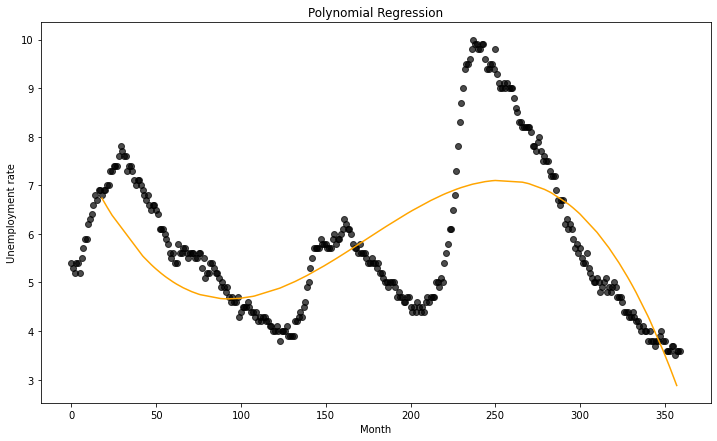

MSE of polynomial: 3.8011299865104737
R2 of polynomial: -0.5412927462127015


In [30]:
tx = np.array(train_x)

#polynomial function
weights = np.polyfit(tx, train_y, 3) #change degree as needed
model = np.poly1d(weights)
pred_poly = model(test_x)

#plot
plt.figure(figsize=(12, 7))
plt.scatter(X, y, facecolor='None', edgecolor='k', alpha=0.7, c="black")
plt.plot(x_test, pred_poly, c="orange") 
plt.xlabel('Month')
plt.ylabel('Unemployment rate')
plt.title("Polynomial Regression")
plt.show()

#mse
mse_poly = mean_squared_error(test_y, pred_poly)
print("MSE of polynomial:",mse_poly)

#R2
r2_poly = r2_score(test_y, pred_poly)
print("R2 of polynomial:",r2_poly)

## Splines (equal knot intervals)

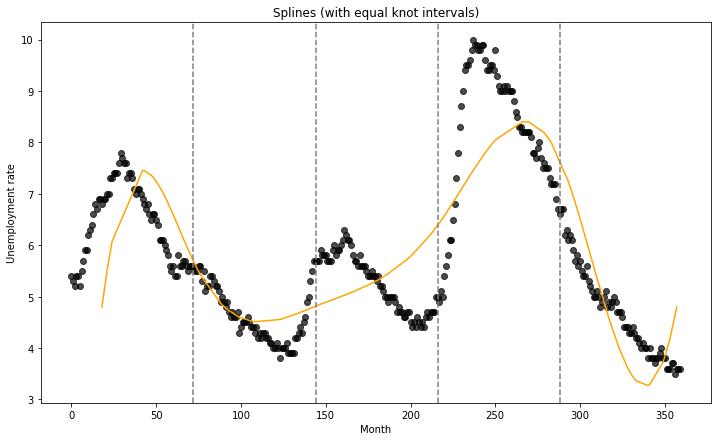

MSE of spline (with equal knot intervals): 5.147042732115924
R2 of spline (with equal knot intervals): -1.0870371851555252


In [31]:
#Splines - equal intervals - degree 3

#finding knots to split data into 5 equal bins
interval = len(X)/5

knot1 = X[0]+interval
knot2 = knot1+interval
knot3 = knot2+interval
knot4 = knot3+interval

#Splines with selected knots
transformed_x = dmatrix("bs(train_x, knots=(knot1,knot2,knot3,knot4), degree=3, include_intercept=False)", {"train": train_x},return_type='dataframe')

#Generalised linear model
fit = sm.GLM(list(train_y), transformed_x).fit()
pred_spline_e = fit.predict(dmatrix("bs(test_x, knots=(knot1,knot2,knot3,knot4), include_intercept=False)", {"valid": test_x}, return_type='dataframe'))

# Plot
plt.figure(figsize=(12, 7))
plt.scatter(X, y, color='black', edgecolor='k', alpha=0.7)
plt.plot(x_test, pred_spline_e, c="orange")
plt.xlabel('Month')
plt.ylabel('Unemployment rate')
plt.title("Splines (with equal knot intervals)")
plt.axvline(x=knot1,ls='--',c="grey")
plt.axvline(x=knot2,ls='--',c="grey")
plt.axvline(x=knot3,ls='--',c="grey")
plt.axvline(x=knot4,ls='--',c="grey")
plt.show()

#mse
mse_spline_e = mean_squared_error(test_y, pred_spline_e)
print("MSE of spline (with equal knot intervals):",mse_spline_e)

#R2
r2_spline_e = r2_score(test_y, pred_spline_e)
print("R2 of spline (with equal knot intervals):",r2_spline_e)

## Splines (Selected knots)

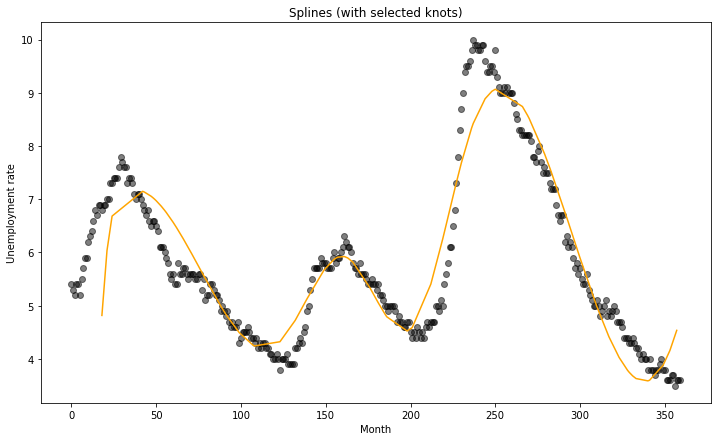

MSE of spline (with selected knots): 5.700778222602462
R2 of spline (with selected knots): -1.3115673900778089


In [32]:
#Splines - selected knots - degree 3

#Splines with selected knots (knot values obtained from interactive plot)
transformed_x = dmatrix("bs(train_x, knots=(29,123,161,203,237), degree=3, include_intercept=False)", {"train": train_x},return_type='dataframe')

#Generalised linear model
fit = sm.GLM(list(train_y), transformed_x).fit()
pred_spline_s = fit.predict(dmatrix("bs(test_x, knots=(29,123,161,203,237), include_intercept=False)", {"valid": test_x}, return_type='dataframe'))

# Plot
plt.figure(figsize=(12, 7))
plt.scatter(X, y, color='black', edgecolor='k', alpha=0.5)
plt.plot(x_test, pred_spline_s, c="orange")
plt.xlabel('Month')
plt.ylabel('Unemployment rate')
plt.title("Splines (with selected knots)")
plt.show()

#mse
mse_spline_s = mean_squared_error(test_y, pred_spline_s)
print("MSE of spline (with selected knots):", mse_spline_s)

#R2
r2_spline_s = r2_score(test_y, pred_spline_s)
print("R2 of spline (with selected knots):", r2_spline_s)

## Multi-Layer Perceptron (ANN)

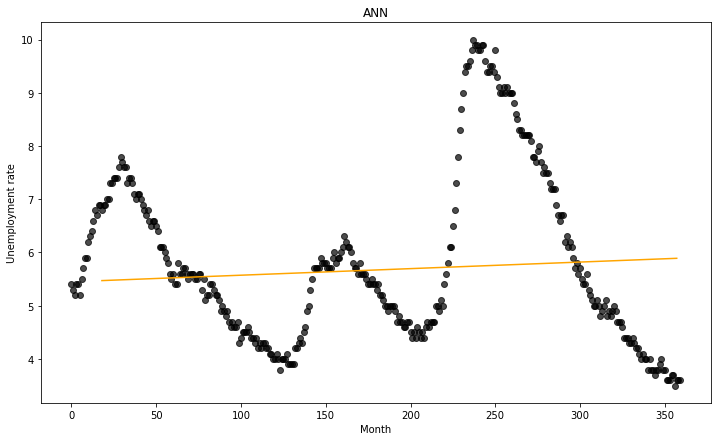

MSE of ANN: 2.443052712752429
R2 of ANN: 0.009384199397674098


In [39]:
#ANN

#remove warnings
warnings.filterwarnings('ignore')
warnings.simplefilter('ignore')

tx = train_x.reshape(-1,1)
ttx = test_x.reshape(-1,1)

##MLP model
mlp = MLPRegressor(hidden_layer_sizes=(3),max_iter=10000,learning_rate_init=0.0001)
model = mlp.fit(tx,train_y)

pred_ann = model.predict(ttx)

plt.figure(figsize=(12, 7))
plt.scatter(X, y, color='black', edgecolor='k', alpha=0.7)
plt.plot(x_test, pred_ann, c="orange")
plt.xlabel('Month')
plt.ylabel('Unemployment rate')
plt.title("ANN")
plt.show()

#mse
mse_ann = mean_squared_error(test_y, pred_ann)
print("MSE of ANN:",mse_ann)

#R2
r2_ann = r2_score(test_y, pred_ann)
print("R2 of ANN:",r2_ann)

## MARS

Earth Model
-----------------------------------------------------
Basis Function                 Pruned  Coefficient   
-----------------------------------------------------
(Intercept)                    No      7.91129       
h(x0-277)                      No      -0.0710596    
h(277-x0)                      No      -0.0498308    
h(x0-215)*h(277-x0)            No      0.00475       
h(215-x0)*h(277-x0)            No      0.00125394    
h(x0-130)*h(215-x0)*h(277-x0)  No      1.19469e-05   
h(130-x0)*h(215-x0)*h(277-x0)  Yes     None          
h(x0-29)*h(215-x0)*h(277-x0)   Yes     None          
h(29-x0)*h(215-x0)*h(277-x0)   No      -2.6177e-06   
h(x0-233)*h(x0-215)*h(277-x0)  No      -9.7779e-05   
h(233-x0)*h(x0-215)*h(277-x0)  No      -0.000276804  
h(x0-322)*h(x0-277)            No      0.000484181   
h(322-x0)*h(x0-277)            No      -0.00126987   
h(x0-160)*h(215-x0)*h(277-x0)  No      -4.28734e-05  
h(160-x0)*h(215-x0)*h(277-x0)  No      3.16254e-05   
h(x0-191)*h(215-

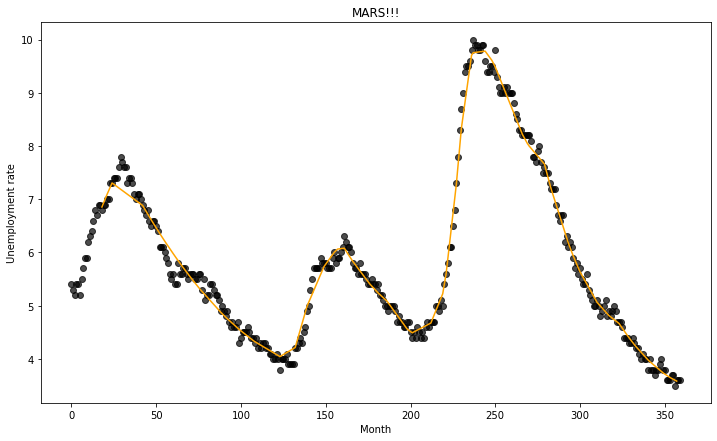

MSE of MARS: 0.022106512245189353
R2 of MARS: 0.9913576039420838


In [34]:
#from anaconda.org, find the following commands to install pyearth and run in Anaconda terminal:

#conda install -c conda-forge sklearn-contrib-py-earth
#conda install -c "conda-forge/label/cf201901" sklearn-contrib-py-earth
#conda install -c "conda-forge/label/cf202003" sklearn-contrib-py-earth 

from pyearth import Earth

#remove warnings
warnings.filterwarnings('ignore')
warnings.simplefilter('ignore')

#MARS
model = Earth(max_degree=3)
model.fit(train_x, train_y) #performs the forward pass, the pruning pass, and a linear fit to determine the final model coefficients.

pred_mars = model.predict(test_x)

print(model.summary())

#plot
plt.figure(figsize=(12, 7))
plt.scatter(X, y, facecolor='None', edgecolor='k', alpha=0.7, c="black")
plt.plot(x_test, pred_mars, c="orange")
plt.xlabel('Month')
plt.ylabel('Unemployment rate')
plt.title("MARS!!!")
plt.show()

#mse
mse_mars = model.mse_
print("MSE of MARS:",mse_mars)

#R2
r2_mars = model.rsq_
print("R2 of MARS:",r2_mars)

## Summary

In [40]:
#Summary of models investigated

method_used = ['Linear Regression', 'Polynomial Regression', 'Splines - with equal knot intervals','Splines - with selected knots','ANN','MARS']
MSE = [mse_linear, mse_poly, mse_spline_e, mse_spline_s, mse_ann, mse_mars]
deg = ['','3','3','3','','3']
R2 = [r2_linear, r2_poly, r2_spline_e, r2_spline_s, r2_ann, r2_mars]
summary_methods = pd.DataFrame({'Method Used':method_used,
                                 'Degree':deg,
                                 'MSE':MSE,
                                 'R_squared':R2})
display(summary_methods)

,Method Used,Degree,MSE,R_squared
0,Linear Regression,,2.499911,-0.013671
1,Polynomial Regression,3,3.801130,-0.541293
2,Splines - with equal knot intervals,3,5.147043,-1.087037
3,Splines - with selected knots,3,5.700778,-1.311567
4,ANN,,2.443053,0.009384
5,MARS,3,0.022107,0.991358


## Appendix

## MARS in 3D !!!

In [42]:
import plotly.graph_objects as go # for data visualization
import plotly.express as px # for data visualization

dict1={}
dict1["year"]=[1950.0,1950.0, 1950.0, 1950.0, 1950.0, 1950.0, 1950.0, 1950.0, 1950.0, 1950.0, 1950.0, 1950.0, 1951.0, 1951.0, 1951.0, 1951.0, 1951.0, 1951.0, 1951.0, 1951.0, 1951.0, 1951.0, 1951.0, 1951.0, 1952.0, 1952.0, 1952.0, 1952.0, 1952.0, 1952.0, 1952.0, 1952.0, 1952.0, 1952.0, 1952.0, 1952.0, 1953.0, 1953.0, 1953.0, 1953.0, 1953.0, 1953.0, 1953.0, 1953.0, 1953.0, 1953.0, 1953.0, 1953.0, 1954.0, 1954.0, 1954.0, 1954.0, 1954.0, 1954.0, 1954.0, 1954.0, 1954.0, 1954.0, 1954.0, 1954.0, 1955.0, 1955.0, 1955.0, 1955.0, 1955.0, 1955.0, 1955.0, 1955.0, 1955.0, 1955.0, 1955.0, 1955.0, 1956.0, 1956.0, 1956.0, 1956.0, 1956.0, 1956.0, 1956.0, 1956.0, 1956.0, 1956.0, 1956.0, 1956.0, 1957.0, 1957.0, 1957.0, 1957.0, 1957.0, 1957.0, 1957.0, 1957.0, 1957.0, 1957.0, 1957.0, 1957.0, 1958.0, 1958.0, 1958.0, 1958.0, 1958.0, 1958.0, 1958.0, 1958.0, 1958.0, 1958.0, 1958.0, 1958.0, 1959.0, 1959.0, 1959.0, 1959.0, 1959.0, 1959.0, 1959.0, 1959.0, 1959.0, 1959.0, 1959.0, 1959.0, 1960.0, 1960.0, 1960.0, 1960.0, 1960.0, 1960.0, 1960.0, 1960.0, 1960.0, 1960.0, 1960.0, 1960.0, 1961.0, 1961.0, 1961.0, 1961.0, 1961.0, 1961.0, 1961.0, 1961.0, 1961.0, 1961.0, 1961.0, 1961.0, 1962.0, 1962.0, 1962.0, 1962.0, 1962.0, 1962.0, 1962.0, 1962.0, 1962.0, 1962.0, 1962.0, 1962.0, 1963.0, 1963.0, 1963.0, 1963.0, 1963.0, 1963.0, 1963.0, 1963.0, 1963.0, 1963.0, 1963.0, 1963.0, 1964.0, 1964.0, 1964.0, 1964.0, 1964.0, 1964.0, 1964.0, 1964.0, 1964.0, 1964.0, 1964.0, 1964.0, 1965.0, 1965.0, 1965.0, 1965.0, 1965.0, 1965.0, 1965.0, 1965.0, 1965.0, 1965.0, 1965.0, 1965.0, 1966.0, 1966.0, 1966.0, 1966.0, 1966.0, 1966.0, 1966.0, 1966.0, 1966.0, 1966.0, 1966.0, 1966.0, 1967.0, 1967.0, 1967.0, 1967.0, 1967.0, 1967.0, 1967.0, 1967.0, 1967.0, 1967.0, 1967.0, 1967.0, 1968.0, 1968.0, 1968.0, 1968.0, 1968.0, 1968.0, 1968.0, 1968.0, 1968.0, 1968.0, 1968.0, 1968.0, 1969.0, 1969.0, 1969.0, 1969.0, 1969.0, 1969.0, 1969.0, 1969.0, 1969.0, 1969.0, 1969.0, 1969.0, 1970.0, 1970.0, 1970.0, 1970.0, 1970.0, 1970.0, 1970.0, 1970.0, 1970.0, 1970.0, 1970.0, 1970.0, 1971.0, 1971.0, 1971.0, 1971.0, 1971.0, 1971.0, 1971.0, 1971.0, 1971.0, 1971.0, 1971.0, 1971.0, 1972.0, 1972.0, 1972.0, 1972.0, 1972.0, 1972.0, 1972.0, 1972.0, 1972.0, 1972.0, 1972.0, 1972.0, 1973.0, 1973.0, 1973.0, 1973.0, 1973.0, 1973.0, 1973.0, 1973.0, 1973.0, 1973.0, 1973.0, 1973.0, 1974.0, 1974.0, 1974.0, 1974.0, 1974.0, 1974.0, 1974.0, 1974.0, 1974.0, 1974.0, 1974.0, 1974.0, 1975.0, 1975.0, 1975.0, 1975.0, 1975.0, 1975.0, 1975.0, 1975.0, 1975.0, 1975.0, 1975.0, 1975.0, 1976.0, 1976.0, 1976.0, 1976.0, 1976.0, 1976.0, 1976.0, 1976.0, 1976.0, 1976.0, 1976.0, 1976.0, 1977.0, 1977.0, 1977.0, 1977.0, 1977.0, 1977.0, 1977.0, 1977.0, 1977.0, 1977.0, 1977.0, 1977.0, 1978.0, 1978.0, 1978.0, 1978.0, 1978.0, 1978.0, 1978.0, 1978.0, 1978.0, 1978.0, 1978.0, 1978.0, 1979.0, 1979.0, 1979.0, 1979.0, 1979.0, 1979.0, 1979.0, 1979.0, 1979.0, 1979.0, 1979.0, 1979.0, 1980.0, 1980.0, 1980.0, 1980.0, 1980.0, 1980.0, 1980.0, 1980.0, 1980.0, 1980.0, 1980.0, 1980.0, 1981.0, 1981.0, 1981.0, 1981.0, 1981.0, 1981.0, 1981.0, 1981.0, 1981.0, 1981.0, 1981.0, 1981.0, 1982.0, 1982.0, 1982.0, 1982.0, 1982.0, 1982.0, 1982.0, 1982.0, 1982.0, 1982.0, 1982.0, 1982.0, 1983.0, 1983.0, 1983.0, 1983.0, 1983.0, 1983.0, 1983.0, 1983.0, 1983.0, 1983.0, 1983.0, 1983.0, 1984.0, 1984.0, 1984.0, 1984.0, 1984.0, 1984.0, 1984.0, 1984.0, 1984.0, 1984.0, 1984.0, 1984.0, 1985.0, 1985.0, 1985.0, 1985.0, 1985.0, 1985.0, 1985.0, 1985.0, 1985.0, 1985.0, 1985.0, 1985.0, 1986.0, 1986.0, 1986.0, 1986.0, 1986.0, 1986.0, 1986.0, 1986.0, 1986.0, 1986.0, 1986.0, 1986.0, 1987.0, 1987.0, 1987.0, 1987.0, 1987.0, 1987.0, 1987.0, 1987.0, 1987.0, 1987.0, 1987.0, 1987.0, 1988.0, 1988.0, 1988.0, 1988.0, 1988.0, 1988.0, 1988.0, 1988.0, 1988.0, 1988.0, 1988.0, 1988.0, 1989.0, 1989.0, 1989.0, 1989.0, 1989.0, 1989.0, 1989.0, 1989.0, 1989.0, 1989.0, 1989.0, 1989.0, 1990.0, 1990.0, 1990.0, 1990.0, 1990.0, 1990.0, 1990.0, 1990.0, 1990.0, 1990.0, 1990.0, 1990.0, 1991.0, 1991.0, 1991.0, 1991.0, 1991.0, 1991.0, 1991.0, 1991.0, 1991.0, 1991.0, 1991.0, 1991.0, 1992.0, 1992.0, 1992.0, 1992.0, 1992.0, 1992.0, 1992.0, 1992.0, 1992.0, 1992.0, 1992.0, 1992.0, 1993.0, 1993.0, 1993.0, 1993.0, 1993.0, 1993.0, 1993.0, 1993.0, 1993.0, 1993.0, 1993.0, 1993.0, 1994.0, 1994.0, 1994.0, 1994.0, 1994.0, 1994.0, 1994.0, 1994.0, 1994.0, 1994.0, 1994.0, 1994.0, 1995.0, 1995.0, 1995.0, 1995.0, 1995.0, 1995.0, 1995.0, 1995.0, 1995.0, 1995.0, 1995.0, 1995.0, 1996.0, 1996.0, 1996.0, 1996.0, 1996.0, 1996.0, 1996.0, 1996.0, 1996.0, 1996.0, 1996.0, 1996.0, 1997.0, 1997.0, 1997.0, 1997.0, 1997.0, 1997.0, 1997.0, 1997.0, 1997.0, 1997.0, 1997.0, 1997.0, 1998.0, 1998.0, 1998.0, 1998.0, 1998.0, 1998.0, 1998.0, 1998.0, 1998.0, 1998.0, 1998.0, 1998.0, 1999.0, 1999.0, 1999.0, 1999.0, 1999.0, 1999.0, 1999.0, 1999.0, 1999.0, 1999.0, 1999.0, 1999.0, 2000.0, 2000.0, 2000.0, 2000.0, 2000.0, 2000.0, 2000.0, 2000.0, 2000.0, 2000.0, 2000.0, 2000.0, 2001.0, 2001.0, 2001.0, 2001.0, 2001.0, 2001.0, 2001.0, 2001.0, 2001.0, 2001.0, 2001.0, 2001.0, 2002.0, 2002.0, 2002.0, 2002.0, 2002.0, 2002.0, 2002.0, 2002.0, 2002.0, 2002.0, 2002.0, 2002.0, 2003.0, 2003.0, 2003.0, 2003.0, 2003.0, 2003.0, 2003.0, 2003.0, 2003.0, 2003.0, 2003.0, 2003.0, 2004.0, 2004.0, 2004.0, 2004.0, 2004.0, 2004.0, 2004.0, 2004.0, 2004.0, 2004.0, 2004.0, 2004.0, 2005.0, 2005.0, 2005.0, 2005.0, 2005.0, 2005.0, 2005.0, 2005.0, 2005.0, 2005.0, 2005.0, 2005.0, 2006.0, 2006.0, 2006.0, 2006.0, 2006.0, 2006.0, 2006.0, 2006.0, 2006.0, 2006.0, 2006.0, 2006.0, 2007.0, 2007.0, 2007.0, 2007.0, 2007.0, 2007.0, 2007.0, 2007.0, 2007.0, 2007.0, 2007.0, 2007.0, 2008.0, 2008.0, 2008.0, 2008.0, 2008.0, 2008.0, 2008.0, 2008.0, 2008.0, 2008.0, 2008.0, 2008.0, 2009.0, 2009.0, 2009.0, 2009.0, 2009.0, 2009.0, 2009.0, 2009.0, 2009.0, 2009.0, 2009.0, 2009.0, 2010.0, 2010.0, 2010.0, 2010.0, 2010.0, 2010.0, 2010.0, 2010.0, 2010.0, 2010.0, 2010.0, 2010.0, 2011.0, 2011.0, 2011.0, 2011.0, 2011.0, 2011.0, 2011.0, 2011.0, 2011.0, 2011.0, 2011.0, 2011.0, 2012.0, 2012.0, 2012.0, 2012.0, 2012.0, 2012.0, 2012.0, 2012.0, 2012.0, 2012.0, 2012.0, 2012.0, 2013.0, 2013.0, 2013.0, 2013.0, 2013.0, 2013.0, 2013.0, 2013.0, 2013.0, 2013.0, 2013.0, 2013.0, 2014.0, 2014.0, 2014.0, 2014.0, 2014.0, 2014.0, 2014.0, 2014.0, 2014.0, 2014.0, 2014.0, 2014.0, 2015.0, 2015.0, 2015.0, 2015.0, 2015.0, 2015.0, 2015.0, 2015.0, 2015.0, 2015.0, 2015.0, 2015.0, 2016.0, 2016.0, 2016.0, 2016.0, 2016.0, 2016.0, 2016.0, 2016.0, 2016.0, 2016.0, 2016.0, 2016.0, 2017.0, 2017.0, 2017.0, 2017.0, 2017.0, 2017.0, 2017.0, 2017.0, 2017.0, 2017.0, 2017.0, 2017.0, 2018.0, 2018.0, 2018.0, 2018.0, 2018.0, 2018.0, 2018.0, 2018.0, 2018.0, 2018.0, 2018.0, 2018.0, 2019.0, 2019.0, 2019.0, 2019.0, 2019.0, 2019.0, 2019.0, 2019.0, 2019.0, 2019.0, 2019.0, 2019.0]
dict1["month"]=[1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0]
dict1["Sunspots"] =[143.9, 134.3, 155.4, 160.6, 150.5, 118.3, 128.9, 120.6, 72.7, 87.0, 77.7, 76.7, 85.0, 84.8, 79.3, 131.7, 153.7, 142.4, 87.2, 86.5, 117.7, 73.3, 74.2, 65.0, 57.9, 32.4, 31.5, 41.7, 33.6, 52.0, 56.1, 77.8, 40.4, 34.2, 31.8, 48.9, 37.9, 5.9, 14.7, 39.6, 18.3, 31.5, 12.7, 33.6, 28.0, 12.3, 2.5, 3.9, 0.4, 0.8, 15.8, 2.7, 1.2, 0.4, 7.3, 12.6, 2.3, 10.5, 13.4, 11.3, 33.4, 29.9, 7.3, 16.4, 41.3, 45.2, 38.2, 58.0, 60.8, 83.0, 126.3, 108.8, 104.1, 175.6, 167.7, 156.7, 193.4, 165.1, 182.7, 240.2, 245.4, 219.9, 285.0, 272.0, 233.7, 184.5, 222.8, 248.0, 233.0, 284.3, 265.1, 223.7, 334.0, 359.4, 298.6, 339.0, 286.7, 233.6, 270.0, 277.6, 248.2, 242.9, 271.0, 283.5, 285.1, 256.9, 215.6, 265.7, 307.7, 202.6, 263.0, 231.3, 243.6, 238.9, 211.9, 282.6, 205.6, 157.7, 175.6, 177.1, 207.2, 149.9, 144.6, 172.7, 169.3, 156.0, 172.4, 190.0, 180.1, 117.3, 126.9, 121.2, 82.1, 65.4, 75.2, 86.9, 72.3, 109.5, 99.3, 79.2, 90.1, 53.7, 46.5, 56.9, 55.1, 71.7, 64.9, 65.9, 61.9, 59.6, 31.4, 31.5, 72.7, 56.1, 38.8, 33.2, 28.7, 35.2, 24.8, 41.7, 61.1, 51.2, 28.7, 47.5, 55.2, 50.1, 33.7, 21.6, 22.6, 25.3, 24.1, 12.9, 14.3, 13.5, 4.8, 13.8, 7.0, 9.2, 11.1, 22.1, 25.4, 20.8, 17.5, 10.2, 34.5, 23.3, 17.3, 13.3, 24.5, 29.1, 22.8, 24.7, 40.3, 35.3, 36.4, 69.0, 64.2, 67.7, 80.2, 72.6, 71.1, 81.2, 81.0, 99.8, 157.0, 132.6, 158.3, 98.4, 122.5, 95.4, 129.5, 151.8, 108.7, 125.0, 133.6, 179.0, 172.5, 158.5, 130.5, 115.0, 180.0, 156.2, 136.2, 154.8, 166.0, 152.5, 121.7, 155.5, 147.8, 170.5, 192.3, 151.1, 169.9, 150.1, 137.1, 138.8, 129.3, 135.4, 132.4, 138.6, 157.9, 180.8, 145.7, 155.1, 180.5, 151.3, 159.3, 131.7, 140.8, 122.6, 134.8, 118.2, 129.2, 111.8, 85.9, 101.6, 81.5, 70.7, 114.7, 87.0, 71.3, 73.4, 89.5, 116.5, 87.0, 125.3, 113.5, 89.6, 113.9, 124.7, 108.3, 108.9, 90.7, 86.9, 59.2, 64.3, 61.8, 60.9, 65.4, 81.8, 60.3, 56.1, 33.2, 36.6, 84.1, 43.7, 34.3, 33.3, 39.4, 37.3, 30.9, 57.5, 56.3, 51.5, 79.1, 47.9, 57.2, 67.2, 35.9, 29.6, 27.3, 16.7, 16.9, 7.7, 13.1, 16.7, 40.4, 56.7, 20.3, 13.6, 27.9, 11.6, 11.9, 6.4, 31.5, 27.3, 18.2, 17.9, 2.9, 24.1, 20.0, 29.7, 7.9, 22.3, 23.8, 33.3, 13.0, 19.0, 27.0, 54.9, 30.6, 43.0, 62.4, 62.1, 41.6, 61.4, 73.7, 132.6, 108.4, 141.2, 117.1, 134.6, 99.7, 82.4, 195.7, 177.1, 138.5, 173.9, 235.9, 194.7, 195.3, 143.7, 190.3, 211.7, 225.7, 201.4, 266.9, 263.6, 259.5, 249.6, 226.1, 219.4, 178.7, 232.2, 254.7, 222.7, 192.9, 191.7, 219.6, 233.3, 209.5, 246.9, 156.6, 189.9, 196.6, 225.3, 194.7, 131.6, 205.3, 242.5, 245.3, 216.2, 186.0, 195.4, 149.8, 230.9, 221.1, 170.3, 119.3, 163.7, 139.4, 161.9, 167.4, 134.3, 127.5, 169.0, 115.5, 73.1, 88.7, 109.6, 132.5, 131.5, 108.9, 96.0, 69.9, 72.5, 45.7, 45.6, 74.8, 110.2, 116.7, 90.4, 96.9, 65.1, 55.7, 35.0, 22.6, 12.6, 26.5, 21.4, 17.8, 20.7, 16.9, 20.4, 32.4, 28.3, 39.9, 10.1, 4.3, 22.0, 17.9, 15.8, 2.8, 27.9, 13.8, 22.4, 16.1, 0.6, 18.1, 9.9, 5.1, 40.1, 15.4, 5.8, 9.8, 3.4, 17.4, 46.0, 39.1, 18.8, 38.2, 47.9, 42.2, 63.4, 48.8, 29.1, 70.5, 45.4, 91.2, 108.8, 74.2, 124.3, 131.4, 139.4, 142.7, 156.5, 156.8, 231.2, 210.1, 208.7, 170.4, 166.3, 195.4, 284.5, 180.5, 232.0, 225.1, 212.2, 238.2, 211.4, 227.4, 171.8, 191.7, 189.7, 175.2, 153.3, 191.1, 252.1, 169.1, 199.4, 178.8, 197.1, 195.3, 240.3, 197.0, 197.6, 166.9, 224.7, 240.2, 240.8, 168.9, 197.1, 159.5, 212.6, 198.3, 230.7, 151.0, 142.2, 94.3, 98.5, 114.2, 91.9, 94.0, 133.4, 129.6, 122.0, 81.4, 127.8, 102.4, 94.4, 78.8, 69.6, 80.4, 62.5, 31.2, 71.1, 48.2, 68.4, 84.9, 54.9, 47.5, 27.4, 29.8, 39.7, 50.6, 34.3, 40.5, 67.1, 29.5, 32.2, 32.6, 45.8, 46.3, 21.6, 19.4, 22.5, 20.4, 18.2, 15.7, 30.6, 14.0, 14.9, 13.3, 7.7, 12.6, 6.8, 7.6, 16.5, 11.8, 19.7, 3.0, 0.7, 24.9, 14.0, 7.4, 11.0, 12.1, 23.0, 25.4, 20.8, 12.9, 35.7, 59.7, 32.8, 50.4, 55.5, 44.5, 50.2, 82.0, 70.6, 74.0, 90.5, 96.7, 121.1, 132.0, 78.5, 97.3, 119.2, 86.0, 98.0, 103.5, 93.6, 149.6, 207.2, 173.5, 142.3, 106.3, 168.7, 188.3, 116.8, 133.1, 165.7, 217.7, 191.5, 165.9, 188.0, 244.3, 180.5, 156.0, 141.6, 158.1, 143.3, 142.6, 121.5, 165.8, 161.7, 142.1, 202.9, 123.0, 161.5, 238.2, 194.1, 176.6, 213.4, 184.6, 170.2, 147.1, 186.9, 187.5, 128.8, 161.0, 175.6, 187.9, 151.2, 147.2, 135.3, 133.5, 75.7, 100.7, 97.9, 86.8, 118.7, 128.3, 115.4, 78.5, 97.8, 82.9, 72.2, 60.6, 74.6, 74.8, 59.2, 72.8, 66.5, 83.8, 69.7, 48.8, 74.2, 70.1, 28.9, 48.1, 43.5, 39.6, 38.7, 61.9, 56.8, 62.4, 60.5, 37.2, 13.2, 27.5, 59.3, 20.9, 5.7, 17.3, 50.3, 37.2, 24.5, 22.2, 20.8, 23.7, 14.9, 35.7, 22.3, 29.3, 18.4, 7.2, 5.4, 19.5, 21.3, 15.1, 9.8, 4.0, 1.5, 2.8, 17.3, 4.1, 2.9, 15.5, 3.6, 4.6, 5.2, 0.6, 0.3, 1.2, 4.2, 6.6, 1.0, 1.3, 1.2, 0.6, 1.2, 2.9, 6.3, 5.5, 0.0, 7.1, 7.7, 6.9, 16.3, 19.5, 28.5, 24.0, 10.4, 13.9, 18.8, 25.2, 29.6, 36.4, 33.6, 34.4, 24.5, 27.3, 48.3, 78.6, 76.1, 58.2, 56.1, 64.5, 65.8, 120.1, 125.7, 139.1, 109.3, 94.4, 47.8, 86.6, 85.9, 96.5, 92.0, 100.1, 94.8, 93.7, 76.5, 87.6, 56.8, 96.1, 60.9, 78.3, 107.3, 120.2, 76.7, 86.2, 91.8, 54.5, 114.4, 113.9, 124.2, 117.0, 146.1, 128.7, 112.5, 112.5, 102.9, 100.2, 106.9, 130.0, 90.0, 103.6, 112.9, 93.0, 66.7, 54.5, 75.3, 88.8, 66.5, 65.8, 64.4, 78.6, 63.6, 62.2, 58.0, 57.0, 56.4, 54.1, 37.9, 51.5, 20.5, 32.4, 50.2, 44.6, 33.4, 21.4, 18.5, 26.1, 26.4, 17.7, 32.3, 18.9, 19.2, 17.8, 32.6, 43.7, 13.2, 5.7, 8.2, 6.8, 10.7, 2.5, 8.9, 13.1, 15.6, 1.6, 8.7, 3.3, 4.9, 4.9, 3.1, 7.7, 0.8, 9.4, 9.1, 9.9, 1.2, 0.9, 0.5, 1.1, 0.4, 0.5, 1.5]
dict1["CME Events"]=[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 6.0, 6.0, 18.0, 18.0, 14.0, 8.0, 23.0, 18.0, 19.0, 19.0, 24.0, 33.0, 18.0, 22.0, 18.0, 26.0, 36.0, 34.0, 31.0, 26.0, 45.0, 41.0, 52.0, 36.0, 62.0, 85.0, 79.0, 88.0, 108.0, 119.0, 0.0, 0.0, 0.0, 34.0, 82.0, 59.0, 0.0, 46.0, 91.0, 83.0, 94.0, 113.0, 136.0, 115.0, 104.0, 84.0, 82.0, 68.0, 93.0, 145.0, 158.0, 141.0, 153.0, 164.0, 147.0, 148.0, 138.0, 117.0, 151.0, 109.0, 105.0, 80.0, 166.0, 124.0, 128.0, 122.0, 82.0, 128.0, 174.0, 158.0, 95.0, 137.0, 116.0, 85.0, 169.0, 174.0, 151.0, 102.0, 161.0, 181.0, 169.0, 171.0, 135.0, 86.0, 127.0, 85.0, 104.0, 153.0, 122.0, 76.0, 55.0, 84.0, 79.0, 110.0, 75.0, 60.0, 89.0, 94.0, 94.0, 88.0, 126.0, 97.0, 109.0, 66.0, 58.0, 103.0, 103.0, 75.0, 112.0, 93.0, 95.0, 106.0, 140.0, 101.0, 145.0, 122.0, 81.0, 76.0, 73.0, 105.0, 102.0, 71.0, 47.0, 80.0, 109.0, 81.0, 125.0, 101.0, 109.0, 73.0, 93.0, 55.0, 106.0, 86.0, 127.0, 161.0, 137.0, 155.0, 141.0, 117.0, 118.0, 102.0, 77.0, 115.0, 97.0, 65.0, 100.0, 80.0, 73.0, 70.0, 76.0, 52.0, 56.0, 67.0, 57.0, 70.0, 62.0, 51.0, 61.0, 60.0, 47.0, 72.0, 47.0, 46.0, 107.0, 65.0, 51.0, 77.0, 64.0, 76.0, 91.0, 86.0, 99.0, 101.0, 94.0, 85.0, 77.0, 78.0, 144.0, 122.0, 84.0, 89.0, 179.0, 205.0, 202.0, 187.0, 140.0, 136.0, 190.0, 227.0, 178.0, 173.0, 155.0, 118.0, 152.0, 172.0, 164.0, 229.0, 241.0, 203.0, 184.0, 136.0, 196.0, 227.0, 227.0, 192.0, 180.0, 206.0, 261.0, 169.0, 136.0, 147.0, 143.0, 254.0, 196.0, 227.0, 211.0, 177.0, 208.0, 226.0, 238.0, 259.0, 191.0, 167.0, 156.0, 211.0, 225.0, 209.0, 178.0, 135.0, 189.0, 200.0, 197.0, 150.0, 179.0, 167.0, 165.0, 168.0, 167.0, 163.0, 172.0, 161.0, 130.0, 123.0, 142.0, 114.0, 112.0, 90.0, 77.0, 89.0, 99.0, 84.0, 70.0, 61.0, 56.0, 92.0, 64.0, 64.0, 72.0, 65.0, 68.0, 71.0, 51.0, 52.0, 37.0, 33.0, 46.0, 48.0, 47.0, 36.0, 39.0, 48.0, 38.0, 40.0, 32.0, 32.0, 48.0, 31.0, 58.0, 39.0, 75.0, 39.0, 57.0, 32.0, 34.0, 48.0, 34.0, 54.0]
dict1["Year_Frac"]=[1950.0833333333333, 1950.1666666666667, 1950.25, 1950.3333333333333, 1950.4166666666667, 1950.5, 1950.5833333333333, 1950.6666666666667, 1950.75, 1950.8333333333333, 1950.9166666666667, 1951.0, 1951.0833333333333, 1951.1666666666667, 1951.25, 1951.3333333333333, 1951.4166666666667, 1951.5, 1951.5833333333333, 1951.6666666666667, 1951.75, 1951.8333333333333, 1951.9166666666667, 1952.0, 1952.0833333333333, 1952.1666666666667, 1952.25, 1952.3333333333333, 1952.4166666666667, 1952.5, 1952.5833333333333, 1952.6666666666667, 1952.75, 1952.8333333333333, 1952.9166666666667, 1953.0, 1953.0833333333333, 1953.1666666666667, 1953.25, 1953.3333333333333, 1953.4166666666667, 1953.5, 1953.5833333333333, 1953.6666666666667, 1953.75, 1953.8333333333333, 1953.9166666666667, 1954.0, 1954.0833333333333, 1954.1666666666667, 1954.25, 1954.3333333333333, 1954.4166666666667, 1954.5, 1954.5833333333333, 1954.6666666666667, 1954.75, 1954.8333333333333, 1954.9166666666667, 1955.0, 1955.0833333333333, 1955.1666666666667, 1955.25, 1955.3333333333333, 1955.4166666666667, 1955.5, 1955.5833333333333, 1955.6666666666667, 1955.75, 1955.8333333333333, 1955.9166666666667, 1956.0, 1956.0833333333333, 1956.1666666666667, 1956.25, 1956.3333333333333, 1956.4166666666667, 1956.5, 1956.5833333333333, 1956.6666666666667, 1956.75, 1956.8333333333333, 1956.9166666666667, 1957.0, 1957.0833333333333, 1957.1666666666667, 1957.25, 1957.3333333333333, 1957.4166666666667, 1957.5, 1957.5833333333333, 1957.6666666666667, 1957.75, 1957.8333333333333, 1957.9166666666667, 1958.0, 1958.0833333333333, 1958.1666666666667, 1958.25, 1958.3333333333333, 1958.4166666666667, 1958.5, 1958.5833333333333, 1958.6666666666667, 1958.75, 1958.8333333333333, 1958.9166666666667, 1959.0, 1959.0833333333333, 1959.1666666666667, 1959.25, 1959.3333333333333, 1959.4166666666667, 1959.5, 1959.5833333333333, 1959.6666666666667, 1959.75, 1959.8333333333333, 1959.9166666666667, 1960.0, 1960.0833333333333, 1960.1666666666667, 1960.25, 1960.3333333333333, 1960.4166666666667, 1960.5, 1960.5833333333333, 1960.6666666666667, 1960.75, 1960.8333333333333, 1960.9166666666667, 1961.0, 1961.0833333333333, 1961.1666666666667, 1961.25, 1961.3333333333333, 1961.4166666666667, 1961.5, 1961.5833333333333, 1961.6666666666667, 1961.75, 1961.8333333333333, 1961.9166666666667, 1962.0, 1962.0833333333333, 1962.1666666666667, 1962.25, 1962.3333333333333, 1962.4166666666667, 1962.5, 1962.5833333333333, 1962.6666666666667, 1962.75, 1962.8333333333333, 1962.9166666666667, 1963.0, 1963.0833333333333, 1963.1666666666667, 1963.25, 1963.3333333333333, 1963.4166666666667, 1963.5, 1963.5833333333333, 1963.6666666666667, 1963.75, 1963.8333333333333, 1963.9166666666667, 1964.0, 1964.0833333333333, 1964.1666666666667, 1964.25, 1964.3333333333333, 1964.4166666666667, 1964.5, 1964.5833333333333, 1964.6666666666667, 1964.75, 1964.8333333333333, 1964.9166666666667, 1965.0, 1965.0833333333333, 1965.1666666666667, 1965.25, 1965.3333333333333, 1965.4166666666667, 1965.5, 1965.5833333333333, 1965.6666666666667, 1965.75, 1965.8333333333333, 1965.9166666666667, 1966.0, 1966.0833333333333, 1966.1666666666667, 1966.25, 1966.3333333333333, 1966.4166666666667, 1966.5, 1966.5833333333333, 1966.6666666666667, 1966.75, 1966.8333333333333, 1966.9166666666667, 1967.0, 1967.0833333333333, 1967.1666666666667, 1967.25, 1967.3333333333333, 1967.4166666666667, 1967.5, 1967.5833333333333, 1967.6666666666667, 1967.75, 1967.8333333333333, 1967.9166666666667, 1968.0, 1968.0833333333333, 1968.1666666666667, 1968.25, 1968.3333333333333, 1968.4166666666667, 1968.5, 1968.5833333333333, 1968.6666666666667, 1968.75, 1968.8333333333333, 1968.9166666666667, 1969.0, 1969.0833333333333, 1969.1666666666667, 1969.25, 1969.3333333333333, 1969.4166666666667, 1969.5, 1969.5833333333333, 1969.6666666666667, 1969.75, 1969.8333333333333, 1969.9166666666667, 1970.0, 1970.0833333333333, 1970.1666666666667, 1970.25, 1970.3333333333333, 1970.4166666666667, 1970.5, 1970.5833333333333, 1970.6666666666667, 1970.75, 1970.8333333333333, 1970.9166666666667, 1971.0, 1971.0833333333333, 1971.1666666666667, 1971.25, 1971.3333333333333, 1971.4166666666667, 1971.5, 1971.5833333333333, 1971.6666666666667, 1971.75, 1971.8333333333333, 1971.9166666666667, 1972.0, 1972.0833333333333, 1972.1666666666667, 1972.25, 1972.3333333333333, 1972.4166666666667, 1972.5, 1972.5833333333333, 1972.6666666666667, 1972.75, 1972.8333333333333, 1972.9166666666667, 1973.0, 1973.0833333333333, 1973.1666666666667, 1973.25, 1973.3333333333333, 1973.4166666666667, 1973.5, 1973.5833333333333, 1973.6666666666667, 1973.75, 1973.8333333333333, 1973.9166666666667, 1974.0, 1974.0833333333333, 1974.1666666666667, 1974.25, 1974.3333333333333, 1974.4166666666667, 1974.5, 1974.5833333333333, 1974.6666666666667, 1974.75, 1974.8333333333333, 1974.9166666666667, 1975.0, 1975.0833333333333, 1975.1666666666667, 1975.25, 1975.3333333333333, 1975.4166666666667, 1975.5, 1975.5833333333333, 1975.6666666666667, 1975.75, 1975.8333333333333, 1975.9166666666667, 1976.0, 1976.0833333333333, 1976.1666666666667, 1976.25, 1976.3333333333333, 1976.4166666666667, 1976.5, 1976.5833333333333, 1976.6666666666667, 1976.75, 1976.8333333333333, 1976.9166666666667, 1977.0, 1977.0833333333333, 1977.1666666666667, 1977.25, 1977.3333333333333, 1977.4166666666667, 1977.5, 1977.5833333333333, 1977.6666666666667, 1977.75, 1977.8333333333333, 1977.9166666666667, 1978.0, 1978.0833333333333, 1978.1666666666667, 1978.25, 1978.3333333333333, 1978.4166666666667, 1978.5, 1978.5833333333333, 1978.6666666666667, 1978.75, 1978.8333333333333, 1978.9166666666667, 1979.0, 1979.0833333333333, 1979.1666666666667, 1979.25, 1979.3333333333333, 1979.4166666666667, 1979.5, 1979.5833333333333, 1979.6666666666667, 1979.75, 1979.8333333333333, 1979.9166666666667, 1980.0, 1980.0833333333333, 1980.1666666666667, 1980.25, 1980.3333333333333, 1980.4166666666667, 1980.5, 1980.5833333333333, 1980.6666666666667, 1980.75, 1980.8333333333333, 1980.9166666666667, 1981.0, 1981.0833333333333, 1981.1666666666667, 1981.25, 1981.3333333333333, 1981.4166666666667, 1981.5, 1981.5833333333333, 1981.6666666666667, 1981.75, 1981.8333333333333, 1981.9166666666667, 1982.0, 1982.0833333333333, 1982.1666666666667, 1982.25, 1982.3333333333333, 1982.4166666666667, 1982.5, 1982.5833333333333, 1982.6666666666667, 1982.75, 1982.8333333333333, 1982.9166666666667, 1983.0, 1983.0833333333333, 1983.1666666666667, 1983.25, 1983.3333333333333, 1983.4166666666667, 1983.5, 1983.5833333333333, 1983.6666666666667, 1983.75, 1983.8333333333333, 1983.9166666666667, 1984.0, 1984.0833333333333, 1984.1666666666667, 1984.25, 1984.3333333333333, 1984.4166666666667, 1984.5, 1984.5833333333333, 1984.6666666666667, 1984.75, 1984.8333333333333, 1984.9166666666667, 1985.0, 1985.0833333333333, 1985.1666666666667, 1985.25, 1985.3333333333333, 1985.4166666666667, 1985.5, 1985.5833333333333, 1985.6666666666667, 1985.75, 1985.8333333333333, 1985.9166666666667, 1986.0, 1986.0833333333333, 1986.1666666666667, 1986.25, 1986.3333333333333, 1986.4166666666667, 1986.5, 1986.5833333333333, 1986.6666666666667, 1986.75, 1986.8333333333333, 1986.9166666666667, 1987.0, 1987.0833333333333, 1987.1666666666667, 1987.25, 1987.3333333333333, 1987.4166666666667, 1987.5, 1987.5833333333333, 1987.6666666666667, 1987.75, 1987.8333333333333, 1987.9166666666667, 1988.0, 1988.0833333333333, 1988.1666666666667, 1988.25, 1988.3333333333333, 1988.4166666666667, 1988.5, 1988.5833333333333, 1988.6666666666667, 1988.75, 1988.8333333333333, 1988.9166666666667, 1989.0, 1989.0833333333333, 1989.1666666666667, 1989.25, 1989.3333333333333, 1989.4166666666667, 1989.5, 1989.5833333333333, 1989.6666666666667, 1989.75, 1989.8333333333333, 1989.9166666666667, 1990.0, 1990.0833333333333, 1990.1666666666667, 1990.25, 1990.3333333333333, 1990.4166666666667, 1990.5, 1990.5833333333333, 1990.6666666666667, 1990.75, 1990.8333333333333, 1990.9166666666667, 1991.0, 1991.0833333333333, 1991.1666666666667, 1991.25, 1991.3333333333333, 1991.4166666666667, 1991.5, 1991.5833333333333, 1991.6666666666667, 1991.75, 1991.8333333333333, 1991.9166666666667, 1992.0, 1992.0833333333333, 1992.1666666666667, 1992.25, 1992.3333333333333, 1992.4166666666667, 1992.5, 1992.5833333333333, 1992.6666666666667, 1992.75, 1992.8333333333333, 1992.9166666666667, 1993.0, 1993.0833333333333, 1993.1666666666667, 1993.25, 1993.3333333333333, 1993.4166666666667, 1993.5, 1993.5833333333333, 1993.6666666666667, 1993.75, 1993.8333333333333, 1993.9166666666667, 1994.0, 1994.0833333333333, 1994.1666666666667, 1994.25, 1994.3333333333333, 1994.4166666666667, 1994.5, 1994.5833333333333, 1994.6666666666667, 1994.75, 1994.8333333333333, 1994.9166666666667, 1995.0, 1995.0833333333333, 1995.1666666666667, 1995.25, 1995.3333333333333, 1995.4166666666667, 1995.5, 1995.5833333333333, 1995.6666666666667, 1995.75, 1995.8333333333333, 1995.9166666666667, 1996.0, 1996.0833333333333, 1996.1666666666667, 1996.25, 1996.3333333333333, 1996.4166666666667, 1996.5, 1996.5833333333333, 1996.6666666666667, 1996.75, 1996.8333333333333, 1996.9166666666667, 1997.0, 1997.0833333333333, 1997.1666666666667, 1997.25, 1997.3333333333333, 1997.4166666666667, 1997.5, 1997.5833333333333, 1997.6666666666667, 1997.75, 1997.8333333333333, 1997.9166666666667, 1998.0, 1998.0833333333333, 1998.1666666666667, 1998.25, 1998.3333333333333, 1998.4166666666667, 1998.5, 1998.5833333333333, 1998.6666666666667, 1998.75, 1998.8333333333333, 1998.9166666666667, 1999.0, 1999.0833333333333, 1999.1666666666667, 1999.25, 1999.3333333333333, 1999.4166666666667, 1999.5, 1999.5833333333333, 1999.6666666666667, 1999.75, 1999.8333333333333, 1999.9166666666667, 2000.0, 2000.0833333333333, 2000.1666666666667, 2000.25, 2000.3333333333333, 2000.4166666666667, 2000.5, 2000.5833333333333, 2000.6666666666667, 2000.75, 2000.8333333333333, 2000.9166666666667, 2001.0, 2001.0833333333333, 2001.1666666666667, 2001.25, 2001.3333333333333, 2001.4166666666667, 2001.5, 2001.5833333333333, 2001.6666666666667, 2001.75, 2001.8333333333333, 2001.9166666666667, 2002.0, 2002.0833333333333, 2002.1666666666667, 2002.25, 2002.3333333333333, 2002.4166666666667, 2002.5, 2002.5833333333333, 2002.6666666666667, 2002.75, 2002.8333333333333, 2002.9166666666667, 2003.0, 2003.0833333333333, 2003.1666666666667, 2003.25, 2003.3333333333333, 2003.4166666666667, 2003.5, 2003.5833333333333, 2003.6666666666667, 2003.75, 2003.8333333333333, 2003.9166666666667, 2004.0, 2004.0833333333333, 2004.1666666666667, 2004.25, 2004.3333333333333, 2004.4166666666667, 2004.5, 2004.5833333333333, 2004.6666666666667, 2004.75, 2004.8333333333333, 2004.9166666666667, 2005.0, 2005.0833333333333, 2005.1666666666667, 2005.25, 2005.3333333333333, 2005.4166666666667, 2005.5, 2005.5833333333333, 2005.6666666666667, 2005.75, 2005.8333333333333, 2005.9166666666667, 2006.0, 2006.0833333333333, 2006.1666666666667, 2006.25, 2006.3333333333333, 2006.4166666666667, 2006.5, 2006.5833333333333, 2006.6666666666667, 2006.75, 2006.8333333333333, 2006.9166666666667, 2007.0, 2007.0833333333333, 2007.1666666666667, 2007.25, 2007.3333333333333, 2007.4166666666667, 2007.5, 2007.5833333333333, 2007.6666666666667, 2007.75, 2007.8333333333333, 2007.9166666666667, 2008.0, 2008.0833333333333, 2008.1666666666667, 2008.25, 2008.3333333333333, 2008.4166666666667, 2008.5, 2008.5833333333333, 2008.6666666666667, 2008.75, 2008.8333333333333, 2008.9166666666667, 2009.0, 2009.0833333333333, 2009.1666666666667, 2009.25, 2009.3333333333333, 2009.4166666666667, 2009.5, 2009.5833333333333, 2009.6666666666667, 2009.75, 2009.8333333333333, 2009.9166666666667, 2010.0, 2010.0833333333333, 2010.1666666666667, 2010.25, 2010.3333333333333, 2010.4166666666667, 2010.5, 2010.5833333333333, 2010.6666666666667, 2010.75, 2010.8333333333333, 2010.9166666666667, 2011.0, 2011.0833333333333, 2011.1666666666667, 2011.25, 2011.3333333333333, 2011.4166666666667, 2011.5, 2011.5833333333333, 2011.6666666666667, 2011.75, 2011.8333333333333, 2011.9166666666667, 2012.0, 2012.0833333333333, 2012.1666666666667, 2012.25, 2012.3333333333333, 2012.4166666666667, 2012.5, 2012.5833333333333, 2012.6666666666667, 2012.75, 2012.8333333333333, 2012.9166666666667, 2013.0, 2013.0833333333333, 2013.1666666666667, 2013.25, 2013.3333333333333, 2013.4166666666667, 2013.5, 2013.5833333333333, 2013.6666666666667, 2013.75, 2013.8333333333333, 2013.9166666666667, 2014.0, 2014.0833333333333, 2014.1666666666667, 2014.25, 2014.3333333333333, 2014.4166666666667, 2014.5, 2014.5833333333333, 2014.6666666666667, 2014.75, 2014.8333333333333, 2014.9166666666667, 2015.0, 2015.0833333333333, 2015.1666666666667, 2015.25, 2015.3333333333333, 2015.4166666666667, 2015.5, 2015.5833333333333, 2015.6666666666667, 2015.75, 2015.8333333333333, 2015.9166666666667, 2016.0, 2016.0833333333333, 2016.1666666666667, 2016.25, 2016.3333333333333, 2016.4166666666667, 2016.5, 2016.5833333333333, 2016.6666666666667, 2016.75, 2016.8333333333333, 2016.9166666666667, 2017.0, 2017.0833333333333, 2017.1666666666667, 2017.25, 2017.3333333333333, 2017.4166666666667, 2017.5, 2017.5833333333333, 2017.6666666666667, 2017.75, 2017.8333333333333, 2017.9166666666667, 2018.0, 2018.0833333333333, 2018.1666666666667, 2018.25, 2018.3333333333333, 2018.4166666666667, 2018.5, 2018.5833333333333, 2018.6666666666667, 2018.75, 2018.8333333333333, 2018.9166666666667, 2019.0, 2019.0833333333333, 2019.1666666666667, 2019.25, 2019.3333333333333, 2019.4166666666667, 2019.5, 2019.5833333333333, 2019.6666666666667, 2019.75, 2019.8333333333333, 2019.9166666666667, 2020.0]

# Read in data
#Data set contains sunsports and CME events from 1996 to 2019
df1=pd.DataFrame(dict1)
df1=df1.dropna()

df1=df1.iloc[0:840,]

df2=df1[["Year_Frac","CME Events","Sunspots"]]


#####Set the dataset for the predictions
X=(df2['Year_Frac'].values)
y=(df2['Sunspots'].values)

degree=2

from pandas._libs.algos import diff_2d
# Note, X in this case is already a 2D array, hence no reshape
df2=df1
df2 = df2[df2['year'] > 1996]  
X3D=df2[['Year_Frac','Sunspots']]
y3D=df2['CME Events']

#MARS
MARS2=Earth(max_degree=degree)
MARS2.fit(X3D,y3D)

# Increments between points in a meshgrid
mesh_sizex = round((X3D['Year_Frac'].max()- X3D['Year_Frac'].min())/20,0)
mesh_sizey = round((X3D['Sunspots'].max()- X3D['Sunspots'].min())/20,0)

# Identify min and max values for input variables
x_min, x_max = X3D['Year_Frac'].min(), X3D['Year_Frac'].max()
y_min, y_max = X3D['Sunspots'].min(), X3D['Sunspots'].max()

# Return evenly spaced values based on a range between min and max
xrange = np.arange(x_min, x_max, mesh_sizex)
yrange = np.arange(y_min, y_max, mesh_sizey)

# Create a meshgrid
xx, yy = np.meshgrid(xrange, yrange)

#Linear regression 
#(to show first how linear regression fit looks like for 3D data)
model1 = LinearRegression()
LR = model1.fit(X3D, y3D)

#print("Simple Linear Regression Model")
#print("--------------------------------------")
#print("Intercept: ", LR.intercept_)
#print("Slope: ", LR.coef_)

#Predict using Linear Reg model
pred_LR = model1.predict(np.c_[xx.ravel(), yy.ravel()])
pred_LR = pred_LR.reshape(xx.shape)

# Predict using MARS model 
z3D_pred = MARS2.predict(np.c_[xx.ravel(), yy.ravel()])
z3D_pred = z3D_pred.reshape(xx.shape)

# Create a 3D scatter plot with predictions
# creating dataset to plot
xs=df2['Year_Frac']
ys=df2['Sunspots']
zs=df2['CME Events']

fig = px.scatter_3d(x=xs, y=ys, z=zs, 
                 opacity=0.8, color_discrete_sequence=['black'])

# Set figure title and colors
fig.update_layout(title_text="Scatter 3D Plot with Linear Reg. Prediction Surface",
                  scene = dict(xaxis=dict(backgroundcolor='white',
                                          color='black',
                                          gridcolor='lightgrey'),
                               yaxis=dict(backgroundcolor='white',
                                          color='black',
                                          gridcolor='lightgrey'
                                          ),
                               zaxis=dict(backgroundcolor='white',
                                          color='black', 
                                          gridcolor='lightgrey')))
# Update marker size
fig.update_traces(marker=dict(size=3))

# Add prediction plane
fig.add_traces(go.Surface(x=xrange, y=yrange, z=pred_LR, name='LR',opacity=.5))

fig.show()

Simple Linear Regression Model
--------------------------------------
Intercept:  -8180.07529671045
Slope:  [4.10280672 0.70669993]


In [13]:
# Create a 3D scatter plot with predictions
# creating dataset to plot
xs=df2['Year_Frac']
ys=df2['Sunspots']
zs=df2['CME Events']

fig2 = px.scatter_3d(x=xs, y=ys, z=zs, 
                 opacity=0.8, color_discrete_sequence=['black'])

# Set figure title and colors
fig2.update_layout(title_text="Scatter 3D Plot with MARS Prediction Surface",
                  scene = dict(xaxis=dict(backgroundcolor='white',
                                          color='black',
                                          gridcolor='lightgrey'),
                               yaxis=dict(backgroundcolor='white',
                                          color='black',
                                          gridcolor='lightgrey'
                                          ),
                               zaxis=dict(backgroundcolor='white',
                                          color='black', 
                                          gridcolor='lightgrey',
                                          range=[0,200])))
# Update marker size
fig2.update_traces(marker=dict(size=3))

# Add prediction plane
fig2.add_traces(go.Surface(x=xrange[1:-1], y=yrange[1:-1], z=z3D_pred[1:-1], name='MARS',opacity =0.8 ))

fig2.show()

# ~ Thank you ~

## Interactive Plot

In [43]:
#used an interactive plot here to get position of knots

x = []
#Data is on monthly basis:
#as of 1st jan 1990 - Month = 0
#as of 1st feb 1990 - Month = 1
#and so on...

for i in range(0,360):
    x.append(i)

X = np.array(x)  #predictor
y = unrate.iloc[504:864]['UNRATE'] #target


import plotly.express as px
fig = px.scatter(x=X, y=y) #add labels
fig.update_traces(marker=dict(color="blue"))
fig.show()